# NB13 - Structuralist Foundations & Chaos Theory Motivation

> **Why RELIC exists**: This notebook explains the *theoretical motivation* behind
> RELIC's architecture. Before learning *how* to use the framework, you must
> understand *why* it is designed this way.

## Learning Objectives

1. **Structuralist Epistemology**: Models are *structural objects*, not trajectory
   approximations. Auditable invariants complement empirical trajectory and process validation.
2. **Lyapunov Predictability**: Chaotic dynamics impose *fundamental limits* on
   trajectory-level validation. This motivates the shift to structural auditing.
3. **From Chaos to DEC**: How Discrete Exterior Calculus provides parameter-independent
   structural guarantees that survive beyond the predictability horizon.
4. **The Three-Layer Conclusion**: Structure -> Budget -> Stability as RELIC's
   unified evidence chain.


## Architecture Anchor

This notebook is aligned with `docs\source\architecture_overview.md` and the relevant theory/API pages under `docs\source`.
All computations below are intended to use actual RELIC functors, the actual simulator or orchestration layer, and real validation pathways rather than notebook-defined pseudo-process equations.


In [1]:
import asyncio
import os
import sys
import warnings
from pathlib import Path

if hasattr(asyncio, "WindowsSelectorEventLoopPolicy"):
    asyncio.set_event_loop_policy(asyncio.WindowsSelectorEventLoopPolicy())

os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'


def locate_project_root() -> Path:
    start = Path.cwd().resolve()
    fallback_paths = [Path(os.environ.get('RELIC_PROJECT_ROOT', Path.cwd())).resolve()]
    for candidate in [start] + list(start.parents) + fallback_paths:
        if (candidate / 'relic').exists() and (candidate / 'docs' / 'source' / 'architecture_overview.md').exists():
            return candidate
    raise RuntimeError(f'Unable to locate RELIC project root from execution directory: {start}')


PROJECT_ROOT = locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

warnings.filterwarnings('ignore', message='The pynvml package is deprecated.*')
warnings.filterwarnings('ignore', category=FutureWarning, module=r'torch\\cuda')

import matplotlib.pyplot as plt
import torch

from relic.core.state import UpdateItem
from relic.orchestration.graph_ir import GraphIR
from relic.orchestration.topology_algebra import (
    build_incidence_matrix,
    compute_cycle_rank,
    compute_left_null_space,
    compute_rank,
    get_topology_signature,
)
from relic.scientific.hydrosphere.evapotranspiration.penman_monteith import PenmanMonteithET
from relic.scientific.hydrosphere.runoff.subsurface import SubsurfaceRunoff
from relic.scientific.hydrosphere.runoff.surface import SurfaceRunoff
from relic.scientific.hydrosphere.soil_moisture.bucket import BucketSoilMoisture


def unwrap_update(value):
    if isinstance(value, UpdateItem):
        return value.value
    return value


def tensor_scalar(value) -> float:
    tensor = torch.as_tensor(unwrap_update(value), dtype=torch.float64).reshape(-1)
    return float(tensor[0].item())


def make_structural_graph() -> GraphIR:
    graph_payload = {
        'schema_version': '1.0',
        'nodes': {
            'atmosphere': {
                'class_type': 'CarbonPool',
                'inputs': {'co2_in': {'type': 'flux'}},
                'outputs': ['co2_out'],
            },
            'vegetation': {
                'class_type': 'CarbonPool',
                'inputs': {'carbon_in': {'type': 'flux'}},
                'outputs': ['carbon_out'],
            },
            'soil': {
                'class_type': 'CarbonPool',
                'inputs': {'litter_in': {'type': 'flux'}},
                'outputs': ['resp_out'],
            },
        },
        'links': [
            {'from': {'node': 'atmosphere', 'port': 'co2_out'}, 'to': {'node': 'vegetation', 'port': 'carbon_in'}},
            {'from': {'node': 'vegetation', 'port': 'carbon_out'}, 'to': {'node': 'soil', 'port': 'litter_in'}},
            {'from': {'node': 'soil', 'port': 'resp_out'}, 'to': {'node': 'atmosphere', 'port': 'co2_in'}},
        ],
    }
    return GraphIR.from_dict(graph_payload)


def make_forcing_series(n_steps: int, dt: float) -> dict:
    step_index = torch.arange(n_steps, dtype=torch.float64)
    time_hours = step_index * dt / 3600.0
    local_hour = torch.remainder(time_hours, 24.0)

    precipitation_flux = torch.zeros(n_steps, dtype=torch.float64)
    storm_one = torch.tensor([0.0019, 0.0021, 0.0023, 0.0025, 0.0027, 0.0029, 0.0031, 0.0029, 0.0027, 0.0025], dtype=torch.float64)
    storm_two = torch.tensor([0.0017, 0.0019, 0.0022, 0.0025, 0.0028, 0.0026, 0.0023, 0.0020], dtype=torch.float64)
    precipitation_flux[18:28] = storm_one
    precipitation_flux[64:72] = storm_two

    solar_cycle = torch.clamp(torch.sin(torch.pi * (local_hour - 6.0) / 12.0), min=0.0)
    net_radiation = 45.0 + 265.0 * torch.pow(solar_cycle, 1.15)
    air_temperature = 291.15 + 5.8 * torch.sin(2.0 * torch.pi * (local_hour - 5.0) / 24.0)
    relative_humidity = 0.78 - 0.22 * solar_cycle
    wind_speed = 1.6 + 1.0 * torch.pow(solar_cycle, 0.7)
    atmospheric_pressure = torch.full((n_steps,), 101325.0, dtype=torch.float64)
    surface_resistance = torch.full((n_steps,), 110.0, dtype=torch.float64)

    return {
        'time_hours': time_hours,
        'precipitation_flux': precipitation_flux,
        'net_radiation': net_radiation,
        'air_temperature': air_temperature,
        'relative_humidity': relative_humidity,
        'wind_speed': wind_speed,
        'atmospheric_pressure': atmospheric_pressure,
        'surface_resistance': surface_resistance,
    }


# References: Manabe (1969); Allen et al. (1998), FAO-56; RELIC hydrology owners.
# Mathematical expression: Delta storage = (P - ET_actual - bucket_runoff - drainage) * dt.
# Parameter meanings: Forcing is an explicit tutorial scenario; outputs use actual Functor kernels.
# Units: Soil storage kg m-2; water rates kg m-2 s-1; meteorology K and Pa; dt seconds.
# Precision: Use float64 throughout this nearly cancelling stock/flux ledger; keep its original acceptance threshold.
# Domain/constraints: PM state-resistance mode, dt <= 3600 s; surface runoff is a separate comparison probe.
# Sign convention: P enters soil; actual ET, bucket runoff and drainage leave it; unused ET demand is not water export.
def run_actual_hydrology_sequence(initial_soil_moisture: float, dt: float = 1800.0, n_steps: int = 96) -> dict:
    forcing = make_forcing_series(n_steps=n_steps, dt=dt)
    suffix = int(round(float(initial_soil_moisture) * 10000.0))
    penman = PenmanMonteithET(name=f'nb13_penman_{suffix}', config={'canopy_resistance_source': 'state'})
    bucket = BucketSoilMoisture(name=f'nb13_bucket_{suffix}')
    surface = SurfaceRunoff(name=f'nb13_surface_{suffix}')
    subsurface = SubsurfaceRunoff(name=f'nb13_subsurface_{suffix}')

    soil_moisture = torch.tensor(float(initial_soil_moisture), dtype=torch.float64)
    groundwater_storage = torch.tensor(0.0, dtype=torch.float64)
    initial_storage = soil_moisture * bucket.soil_depth.to(dtype=torch.float64) * torch.as_tensor(bucket.water_density, dtype=torch.float64)

    et_history = []
    et_demand_history = []
    bucket_runoff_history = []
    surface_runoff_history = []
    drainage_history = []
    infiltration_history = []
    subsurface_runoff_history = []
    groundwater_storage_history = [groundwater_storage.detach().clone()]
    soil_moisture_history = [soil_moisture.detach().clone()]
    soil_storage_history = [initial_storage.detach().clone()]

    for step_idx in range(n_steps):
        current_time = float(step_idx) * dt
        penman_updates = penman(
            {
                'net_radiation': forcing['net_radiation'][step_idx],
                'air_temperature': forcing['air_temperature'][step_idx],
                'wind_speed': forcing['wind_speed'][step_idx],
                'atmospheric_pressure': forcing['atmospheric_pressure'][step_idx],
                'relative_humidity': forcing['relative_humidity'][step_idx],
                'surface_resistance': forcing['surface_resistance'][step_idx],
            },
            time=current_time,
            dt=dt,
        )
        evapotranspiration_flux = torch.as_tensor(unwrap_update(penman_updates['evapotranspiration_flux']), dtype=torch.float64)

        bucket_updates = bucket(
            {
                'soil_moisture': soil_moisture,
                'precipitation_flux': forcing['precipitation_flux'][step_idx],
                'evapotranspiration_flux': evapotranspiration_flux,
            },
            time=current_time,
            dt=dt,
        )
        actual_et = torch.as_tensor(bucket_updates['diagnostics.soil_moisture_bucket']['adjusted_evapotranspiration'], dtype=torch.float64)
        assert bool(torch.isfinite(actual_et)) and 0.0 <= float(actual_et) <= float(evapotranspiration_flux)
        soil_moisture = torch.as_tensor(unwrap_update(bucket_updates['soil_moisture']), dtype=torch.float64)
        bucket_surface_runoff_flux = torch.as_tensor(unwrap_update(bucket_updates['surface_runoff_flux']), dtype=torch.float64)
        drainage_flux = torch.as_tensor(unwrap_update(bucket_updates['drainage_flux']), dtype=torch.float64)
        soil_water_storage = soil_moisture * bucket.soil_depth.to(dtype=torch.float64) * torch.as_tensor(bucket.water_density, dtype=torch.float64)

        surface_updates = surface(
            {
                'soil_moisture': soil_moisture,
                'precipitation_flux': forcing['precipitation_flux'][step_idx],
            },
            time=current_time,
            dt=dt,
        )
        surface_runoff_flux = torch.as_tensor(unwrap_update(surface_updates['surface_runoff_flux']), dtype=torch.float64)
        infiltration_flux = torch.as_tensor(unwrap_update(surface_updates['infiltration_flux']), dtype=torch.float64)

        subsurface_updates = subsurface(
            {
                'soil_moisture': soil_moisture,
                'groundwater_storage': groundwater_storage,
                'drainage_flux': drainage_flux,
            },
            time=current_time,
            dt=dt,
        )
        groundwater_storage = torch.as_tensor(unwrap_update(subsurface_updates['groundwater_storage']), dtype=torch.float64)
        subsurface_runoff_flux = torch.as_tensor(unwrap_update(subsurface_updates['subsurface_runoff_flux']), dtype=torch.float64)

        et_history.append(actual_et.detach().clone())
        et_demand_history.append(evapotranspiration_flux.detach().clone())
        bucket_runoff_history.append(bucket_surface_runoff_flux.detach().clone())
        surface_runoff_history.append(surface_runoff_flux.detach().clone())
        drainage_history.append(drainage_flux.detach().clone())
        infiltration_history.append(infiltration_flux.detach().clone())
        subsurface_runoff_history.append(subsurface_runoff_flux.detach().clone())
        soil_moisture_history.append(soil_moisture.detach().clone())
        groundwater_storage_history.append(groundwater_storage.detach().clone())
        soil_storage_history.append(soil_water_storage.detach().clone())

    result = {
        'time_hours': forcing['time_hours'],
        'precipitation_flux': forcing['precipitation_flux'],
        'air_temperature': forcing['air_temperature'],
        'net_radiation': forcing['net_radiation'],
        'evapotranspiration_flux': torch.stack(et_history),
        'potential_evapotranspiration_flux': torch.stack(et_demand_history),
        'unrealized_evapotranspiration_flux': torch.stack(et_demand_history) - torch.stack(et_history),
        'bucket_surface_runoff_flux': torch.stack(bucket_runoff_history),
        'surface_runoff_flux': torch.stack(surface_runoff_history),
        'drainage_flux': torch.stack(drainage_history),
        'infiltration_flux': torch.stack(infiltration_history),
        'subsurface_runoff_flux': torch.stack(subsurface_runoff_history),
        'soil_moisture': torch.stack(soil_moisture_history),
        'groundwater_storage': torch.stack(groundwater_storage_history),
        'soil_water_storage': torch.stack(soil_storage_history),
    }
    result['storage_change'] = result['soil_water_storage'][1:] - result['soil_water_storage'][:-1]
    result['budget_rhs'] = (
        result['precipitation_flux']
        - result['evapotranspiration_flux']
        - result['bucket_surface_runoff_flux']
        - result['drainage_flux']
    ) * dt
    result['budget_residual'] = result['storage_change'] - result['budget_rhs']
    return result


print(f'Project root : {PROJECT_ROOT}')
print(f'PyTorch      : {torch.__version__}')
print('[OK] NB13 environment ready with actual RELIC topology and hydrology helpers')

Project root : <RELIC_ROOT>
PyTorch      : 2.13.0+cu130
[OK] NB13 environment ready with actual RELIC topology and hydrology helpers


## Part 1: Structuralist Epistemology

### The Problem with Trajectory Validation

Traditional Earth System Models (ESMs) are validated by comparing simulated
*trajectories* against observations:

$$\text{Error}(t) = \|x_{\text{sim}}(t) - x_{\text{obs}}(t)\|$$

This seems natural, but it faces a **fundamental problem**: for chaotic systems
with a positive relevant Lyapunov exponent, nearby trajectories can separate
rapidly. This does not establish chaos for every ESM or remove the need for
observational and statistical validation.

### The RELIC Alternative: Structural Validation

RELIC adopts a **structuralist** view (inspired by the Semantic View of Theories
in philosophy of science):

> Structural invariants provide auditable constraints alongside observational
> skill, process validity, and numerical verification; none replaces the others.

This means we validate:
- **Conservation laws** (mass, energy, carbon budgets)
- **Topological structure** (dependency graph invariants)
- **Budget residuals** (auditable deviations from exact conservation)

Rather than asking "*Does the trajectory match?*", we ask "*Are the structural
constraints satisfied?*"


## Part 2: Lyapunov Exponents & Predictability Limits

### Why Trajectories Cannot Be Trusted

The **maximum Lyapunov exponent** $\lambda_{\max}$ quantifies the rate of
exponential divergence between nearby trajectories:

$$\|\delta x(t)\| \approx e^{\lambda_{\max} t} \|\delta x_0\|$$

When $\lambda_{\max} > 0$, the **predictability horizon** is:

$$T_p \approx \frac{1}{\lambda_{\max}} \ln\left(\frac{\Delta_{\max}}{\|\delta x_0\|}\right)$$

This estimate is conditional on an exponential separation regime and the
stated error threshold. It does not invalidate ensemble or statistical
comparison with observations.

The cells below compare two actual RELIC hydrology response sequences.
They do not integrate a Lorenz system, estimate a Lyapunov exponent, or
claim that the observed finite-time separation proves chaos.


In [2]:
# ---------------------------------------------------------------
# References:
#   Rodriguez-Iturbe and Porporato (2004), Ecohydrology of water-controlled ecosystems.
#   Manabe (1969), Monthly Weather Review, 97(11), 739-774.
#   RELIC hydrology functors: PenmanMonteithET, BucketSoilMoisture, SurfaceRunoff, SubsurfaceRunoff.
# Mathematical expression:
#   ET_t = PenmanMonteithET(meteorology_t)
#   theta_{t+1} = BucketSoilMoisture(theta_t, P_t, ET_t, dt)
#   Delta_q(t) = q_perturbed(t) - q_reference(t)
# Parameter meanings:
#   initial_soil_moisture: initial volumetric soil water content [m3 m-3]
#   moisture_damping_ratio: final-to-initial soil-moisture separation across two actual trajectories
#   runoff_divergence: absolute surface-runoff separation between two executed RELIC trajectories
# ---------------------------------------------------------------

hydro_ref = run_actual_hydrology_sequence(initial_soil_moisture=0.2980, dt=1800.0, n_steps=96)
hydro_pert = run_actual_hydrology_sequence(initial_soil_moisture=0.3015, dt=1800.0, n_steps=96)

initial_theta_separation = float(torch.abs(hydro_pert['soil_moisture'][0] - hydro_ref['soil_moisture'][0]).item())
final_theta_separation = float(torch.abs(hydro_pert['soil_moisture'][-1] - hydro_ref['soil_moisture'][-1]).item())
moisture_divergence = torch.abs(hydro_pert['soil_moisture'][1:] - hydro_ref['soil_moisture'][1:])
runoff_divergence = torch.abs(hydro_pert['surface_runoff_flux'] - hydro_ref['surface_runoff_flux'])
subsurface_divergence = torch.abs(hydro_pert['subsurface_runoff_flux'] - hydro_ref['subsurface_runoff_flux'])
moisture_damping_ratio = final_theta_separation / max(initial_theta_separation, 1.0e-12)

print('=== Actual RELIC Hydrology: Trajectory Sensitivity Diagnostics ===')
print(f"  dt [s]:                        1800.0")
print(f"  Initial theta reference:       {hydro_ref['soil_moisture'][0].item():.4f}")
print(f"  Initial theta perturbed:       {hydro_pert['soil_moisture'][0].item():.4f}")
print(f"  Initial theta separation:      {initial_theta_separation:.6e}")
print(f"  Final theta separation:        {final_theta_separation:.6e}")
print(f"  Moisture damping ratio:        {moisture_damping_ratio:.3f}")
print(f"  Max soil-moisture divergence:  {float(torch.max(moisture_divergence).item()):.6e}")
print(f"  Max surface-runoff divergence: {float(torch.max(runoff_divergence).item()):.6e}")
print(f"  Max subsurface divergence:     {float(torch.max(subsurface_divergence).item()):.6e}")
print('[OK] Sensitivity diagnostics now come from an actual RELIC hydrology chain and report what the executed trajectories really do.')

<USER_HOME>\AppData\Local\Temp\ipykernel_60292\1213235657.py:174: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:823.)
  assert bool(torch.isfinite(actual_et)) and 0.0 <= float(actual_et) <= float(evapotranspiration_flux)


=== Actual RELIC Hydrology: Trajectory Sensitivity Diagnostics ===
  dt [s]:                        1800.0
  Initial theta reference:       0.2980
  Initial theta perturbed:       0.3015
  Initial theta separation:      3.500000e-03
  Final theta separation:        0.000000e+00
  Moisture damping ratio:        0.000
  Max soil-moisture divergence:  2.029769e-03
  Max surface-runoff divergence: 0.000000e+00
  Max subsurface divergence:     1.127649e-03
[OK] Sensitivity diagnostics now come from an actual RELIC hydrology chain and report what the executed trajectories really do.


## Part 3: Structural Invariants Survive Beyond the Predictability Horizon

The key insight is that while *trajectories* diverge, certain *structural properties*
remain invariant:

| Property | Trajectory-Dependent? | Survives Chaos? |
|---|---|---|
| Point-wise state $x(t)$ | Yes | No |
| Conservation law $\mathbf{1}^\top u = \text{const}$ | No | **Yes** |
| Topological fingerprint $\sigma(\mathcal{G})$ | No | **Yes** |
| Budget residual $\mathcal{R}_{\Delta t}$ | Numerical only | **Yes (auditable)** |

This is the philosophical foundation of RELIC: **we do not promise trajectory accuracy;
we promise auditable structural constraints.**


In [3]:
# References:
#   Godsil and Royle (2001), Algebraic Graph Theory, Definition 8.1.1.
#   RELIC orchestration modules: graph_ir.py and topology_algebra.py.
# Mathematical expression:
#   B[i, j] = -1 for the source node of link j, +1 for the target node, 0 otherwise
#   kappa = dim ker(B^T) = n - rank(B)
#   beta_1 = dim ker(B) = m - rank(B)
# Parameter meanings:
#   graph: actual GraphIR object used for topology inspection
#   B_torch: incidence matrix exported by RELIC topology_algebra and analyzed with torch
#   sig: actual topology signature returned by RELIC

# This schematic GraphIR is inspected only; CarbonPool is not resolved or executed.
graph = make_structural_graph()
B_numpy, node_ids, link_indices = build_incidence_matrix(graph)
B_torch = torch.as_tensor(B_numpy, dtype=torch.float64)
sig = get_topology_signature(graph)
rank = int(compute_rank(B_numpy))
n, m = map(int, B_torch.shape)
kappa = int(sig['nullity'])
beta_1 = int(sig['betti_number'])

print('=== Actual GraphIR Incidence Matrix for the Carbon Cycle ===')
print(f'Nodes      : {node_ids}')
print(f'Link count : {len(link_indices)}')
print('B =')
print(B_torch)
print()
print('=== Topological Fingerprint sigma(G) ===')
print(f'n (nodes)                = {n}')
print(f'm (links)                = {m}')
print(f'rank(B)                  = {rank}')
print(f'kappa = dim ker(B^T)     = {kappa}')
print(f'beta_1 = dim ker(B)      = {beta_1}')
print(f'sigma(G)                 = ({n}, {m}, {rank}, {kappa}, {beta_1})')
print('[OK] The incidence matrix and topology signature come directly from RELIC GraphIR utilities.')

=== Actual GraphIR Incidence Matrix for the Carbon Cycle ===
Nodes      : ['atmosphere', 'soil', 'vegetation']
Link count : 3
B =
tensor([[-1.,  0.,  1.],
        [ 0.,  1., -1.],
        [ 1., -1.,  0.]], dtype=torch.float64)

=== Topological Fingerprint sigma(G) ===
n (nodes)                = 3
m (links)                = 3
rank(B)                  = 2
kappa = dim ker(B^T)     = 1
beta_1 = dim ker(B)      = 1
sigma(G)                 = (3, 3, 2, 1, 1)
[OK] The incidence matrix and topology signature come directly from RELIC GraphIR utilities.


## Part 4: Algebraic Conservation Proof

### Theorem (Structural Conservation)

For any $c \in \ker(\mathbf{B}^\top)$ and dynamics $\frac{du}{dt} = \mathbf{B}f(u)$:

$$\frac{d}{dt}(c^\top u) = c^\top \mathbf{B} f(u) = (\mathbf{B}^\top c)^\top f(u) = 0$$

This is an **algebraic identity** -- it holds regardless of:
- The functional form of $f(u)$ (any process model)
- The parameter values
- Continuous-time evaluation; a discrete scheme requires its own preservation proof
- Whether the system is chaotic or stable

### Corollary (Total Mass Conservation)

Since $\mathbf{B}^\top \mathbf{1} = \mathbf{0}$ (column sums are zero),
$\mathbf{1}^\top u(t) = \text{const}$ -- total mass is conserved.

The GraphIR in this exercise is a schematic incidence example, not a
compiled model. Physical stores, units, supports and actual transfer laws
must be bound before calling its null-space vectors physical ledgers.


In [4]:
# Compute left null space = conservation vectors from the actual GraphIR incidence matrix
left_null_vectors = torch.as_tensor(compute_left_null_space(B_numpy), dtype=torch.float64)
left_null_residual = torch.matmul(B_torch.T, left_null_vectors[0])

print('=== Conservation Vectors from RELIC Topology Algebra ===')
for idx in range(left_null_vectors.shape[0]):
    print(f'c_{idx + 1} = {left_null_vectors[idx]}')
print()
print(f'B^T * c_1 = {left_null_residual}')
print(f'Max |B^T c_1| = {float(torch.max(torch.abs(left_null_residual)).item()):.6e}')
print()

# Budget closure for the actual bucket hydrology trajectory
actual_storage_change = torch.sum(hydro_ref['storage_change'])
expected_storage_change = torch.sum(hydro_ref['budget_rhs'])
cumulative_budget_residual = actual_storage_change - expected_storage_change
relative_budget_residual = float(torch.abs(cumulative_budget_residual / torch.clamp(torch.abs(expected_storage_change), min=1.0e-8)).item())

print('=== Actual Bucket Water-Balance Audit ===')
print(f"Initial storage [kg m-2] : {float(hydro_ref['soil_water_storage'][0].item()):.6f}")
print(f"Final storage [kg m-2]   : {float(hydro_ref['soil_water_storage'][-1].item()):.6f}")
print(f"Delta storage [kg m-2]   : {float(actual_storage_change.item()):.6f}")
print(f"Flux-integrated RHS      : {float(expected_storage_change.item()):.6f}")
print(f"Residual [kg m-2]        : {float(cumulative_budget_residual.item()):.6e}")
print(f"Relative residual        : {relative_budget_residual:.6e}")
print(f"Max step residual        : {float(torch.max(torch.abs(hydro_ref['budget_residual'])).item()):.6e}")
print('[OK] Conservation evidence now uses actual RELIC topology plus an executed bucket water-balance audit.')

=== Conservation Vectors from RELIC Topology Algebra ===
c_1 = tensor([0.5774, 0.5774, 0.5774], dtype=torch.float64)

B^T * c_1 = tensor([0., 0., 0.], dtype=torch.float64)
Max |B^T c_1| = 0.000000e+00

=== Actual Bucket Water-Balance Audit ===
Initial storage [kg m-2] : 298.000000
Final storage [kg m-2]   : 298.331697
Delta storage [kg m-2]   : 0.331697
Flux-integrated RHS      : 0.331697
Residual [kg m-2]        : 6.463718e-13
Relative residual        : 1.948681e-12
Max step residual        : 5.684342e-14
[OK] Conservation evidence now uses actual RELIC topology plus an executed bucket water-balance audit.


## Part 5: Hodge Decomposition -- Gradient Flow vs Cycle Flow

### Theorem (Edge Space Decomposition)

$$\mathbb{R}^m = \text{im}(\mathbf{B}^\top) \oplus \ker(\mathbf{B})$$

- $\text{im}(\mathbf{B}^\top)$: **Gradient flows** -- driven by potential differences
  between nodes. Observable from stock data.
- $\ker(\mathbf{B})$: **Cycle flows** -- circulate within feedback loops.
  **Unobservable from stock data alone.**

### Earth System Implication

In carbon/nitrogen/water cycles, internal recycling rates (cycle flows)
**cannot be uniquely determined** from pool-size observations. You need
independent flux measurements or regularization assumptions.


In [5]:
# Hodge decomposition for the actual carbon-cycle GraphIR
# References:
#   Strang (1988), Section 3.1: Four fundamental subspaces.
#   RELIC topology_algebra utilities for rank and cycle diagnostics.
# Mathematical expression:
#   R^m = im(B^T) (+) ker(B)
#   dim ker(B) = beta_1 = m - rank(B)
# Parameter meanings:
#   cycle_basis: right-null-space basis of B corresponding to internal cycle flows
#   gradient_dim: dimension of image(B^T)
#   beta_1: cycle dimension obtained from the actual GraphIR

U_hodge, sigma_hodge, Vh_hodge = torch.linalg.svd(B_torch, full_matrices=True)
cycle_basis = Vh_hodge[rank:, :]
gradient_dim = rank

print('=== Hodge Decomposition on the Actual GraphIR ===')
print(f'Edge space dimension      : {m}')
print(f'Gradient subspace dim     : {gradient_dim}')
print(f'Cycle subspace dim        : {beta_1}')
print(f'Cycle rank from RELIC API : {int(compute_cycle_rank(B_numpy))}')
print()

if cycle_basis.shape[0] > 0:
    cycle_vector = cycle_basis[0]
    cycle_residual = torch.matmul(B_torch, cycle_vector)
    print(f'Cycle basis vector        : {cycle_vector}')
    print(f'B * cycle_vector          : {cycle_residual}')
    print(f'Max |B * cycle_vector|    : {float(torch.max(torch.abs(cycle_residual)).item()):.6e}')
    print('Interpretation            : this internal circulation leaves node stocks unchanged.')
else:
    print('No cycle basis found; the graph is tree-like.')

=== Hodge Decomposition on the Actual GraphIR ===
Edge space dimension      : 3
Gradient subspace dim     : 2
Cycle subspace dim        : 1
Cycle rank from RELIC API : 1

Cycle basis vector        : tensor([0.5774, 0.5774, 0.5774], dtype=torch.float64)
B * cycle_vector          : tensor([ 2.2204e-16, -1.1102e-16, -1.1102e-16], dtype=torch.float64)
Max |B * cycle_vector|    : 2.220446e-16
Interpretation            : this internal circulation leaves node stocks unchanged.


## Part 6: The Three-Layer Evidence Chain

RELIC organizes its auditing into three layers, each providing progressively
more detailed information:

### Layer 1: Structural Quantities (Parameter-Independent)

$$\sigma(\mathcal{G}) = (n, m, \text{rank}(\mathbf{B}), \kappa, \beta_1)$$

These are computed once from the graph topology and serve as a **structural
version number**. If two model configurations have different $\sigma$, they are
structurally different models -- no parameter tuning can make them equivalent.

### Layer 2: Budget Quantities (Numerically Auditable)

$$\mathcal{R}_{\Delta t} = \Delta S - (\sum F_{\text{in}} - \sum F_{\text{out}})\Delta t$$

Budget residuals quantify how well conservation is maintained during numerical
integration. Non-zero residuals indicate flux omissions, coupling inconsistencies,
or boundary clipping.

### Layer 3: Stability Quantities (Timestep Constraints)

$$\text{CFL} = \frac{u \cdot \Delta t}{\Delta x} \leq 1$$

Stability numbers provide computable upper bounds on $\Delta t$, linking
computational cost to diagnostic interpretability.

> **RELIC's Promise**: We do not promise trajectory accuracy beyond the Lyapunov
> predictability horizon. We promise that the structural constraints, budget
> residuals, and stability diagnostics form an **auditable evidence chain**.


In [6]:
# Demonstrate the three-layer chain with actual RELIC outputs
structural_ok = float(torch.max(torch.abs(left_null_residual)).item()) <= 1.0e-10
budget_ok = relative_budget_residual <= 1.0e-3
assert structural_ok, 'Graph null-space identity failed.'
assert budget_ok, 'Actual bucket water-budget residual exceeds the tutorial criterion.'

print('=== RELIC Three-Layer Evidence Chain ===')
print()
print('Layer 1: STRUCTURAL (parameter-independent)')
print(f'  sigma(G)                = ({n}, {m}, {rank}, {kappa}, {beta_1})')
print(f'  Max |B^T c|             = {float(torch.max(torch.abs(left_null_residual)).item()):.6e}')
print(f'  Status                  = {"PASS" if structural_ok else "FAIL"}')
print()
print('Layer 2: BUDGET (runtime auditable)')
print(f'  Cumulative residual     = {float(cumulative_budget_residual.item()):.6e} kg m-2')
print(f'  Relative residual       = {relative_budget_residual:.6e}')
print(f'  Max step residual       = {float(torch.max(torch.abs(hydro_ref["budget_residual"])).item()):.6e} kg m-2')
print(f'  Status                  = {"PASS" if budget_ok else "FAIL"}')
print()
print('Layer 3: TRAJECTORY SENSITIVITY (executed dynamics)')
print(f'  Initial theta separation= {initial_theta_separation:.6e}')
print(f'  Final theta separation  = {final_theta_separation:.6e}')
print(f'  Damping ratio           = {moisture_damping_ratio:.3f}')
print(f'  Peak subsurface delta   = {float(torch.max(subsurface_divergence).item()):.6e}')
print(f'  Peak surface delta      = {float(torch.max(runoff_divergence).item()):.6e}')
print('  Status                  = DIAGNOSTIC')
print()
print('[OK] The notebook now separates structural invariants, executed budget closure, and actual trajectory sensitivity using RELIC calculations.')

=== RELIC Three-Layer Evidence Chain ===

Layer 1: STRUCTURAL (parameter-independent)
  sigma(G)                = (3, 3, 2, 1, 1)
  Max |B^T c|             = 0.000000e+00
  Status                  = PASS

Layer 2: BUDGET (runtime auditable)
  Cumulative residual     = 6.463718e-13 kg m-2
  Relative residual       = 1.948681e-12
  Max step residual       = 5.684342e-14 kg m-2
  Status                  = PASS

Layer 3: TRAJECTORY SENSITIVITY (executed dynamics)
  Initial theta separation= 3.500000e-03
  Final theta separation  = 0.000000e+00
  Damping ratio           = 0.000
  Peak subsurface delta   = 1.127649e-03
  Peak surface delta      = 0.000000e+00
  Status                  = DIAGNOSTIC

[OK] The notebook now separates structural invariants, executed budget closure, and actual trajectory sensitivity using RELIC calculations.


## Part 7: How This Maps to RELIC Code

| Theory Concept | RELIC Implementation |
|---|---|
| Incidence matrix $\mathbf{B}$ | `relic.orchestration.topology_algebra.build_incidence_matrix()` |
| Conservation vectors $\ker(\mathbf{B}^\top)$ | `relic.orchestration.topology_algebra.compute_left_null_space()` |
| Topological fingerprint $\sigma$ | `relic.orchestration.topology_algebra.get_topology_signature()` |
| Budget residual $\mathcal{R}_{\Delta t}$ | `StateManager.generate_conservation_report()` |
| CFL / stability check | `relic.scientific.transport` (CFL condition) |
| Transactional state update | `StateManager.apply_updates()` with clip_loss |

In the next notebook (NB14), we will use these RELIC APIs directly to build
and audit a real Functor dependency graph.


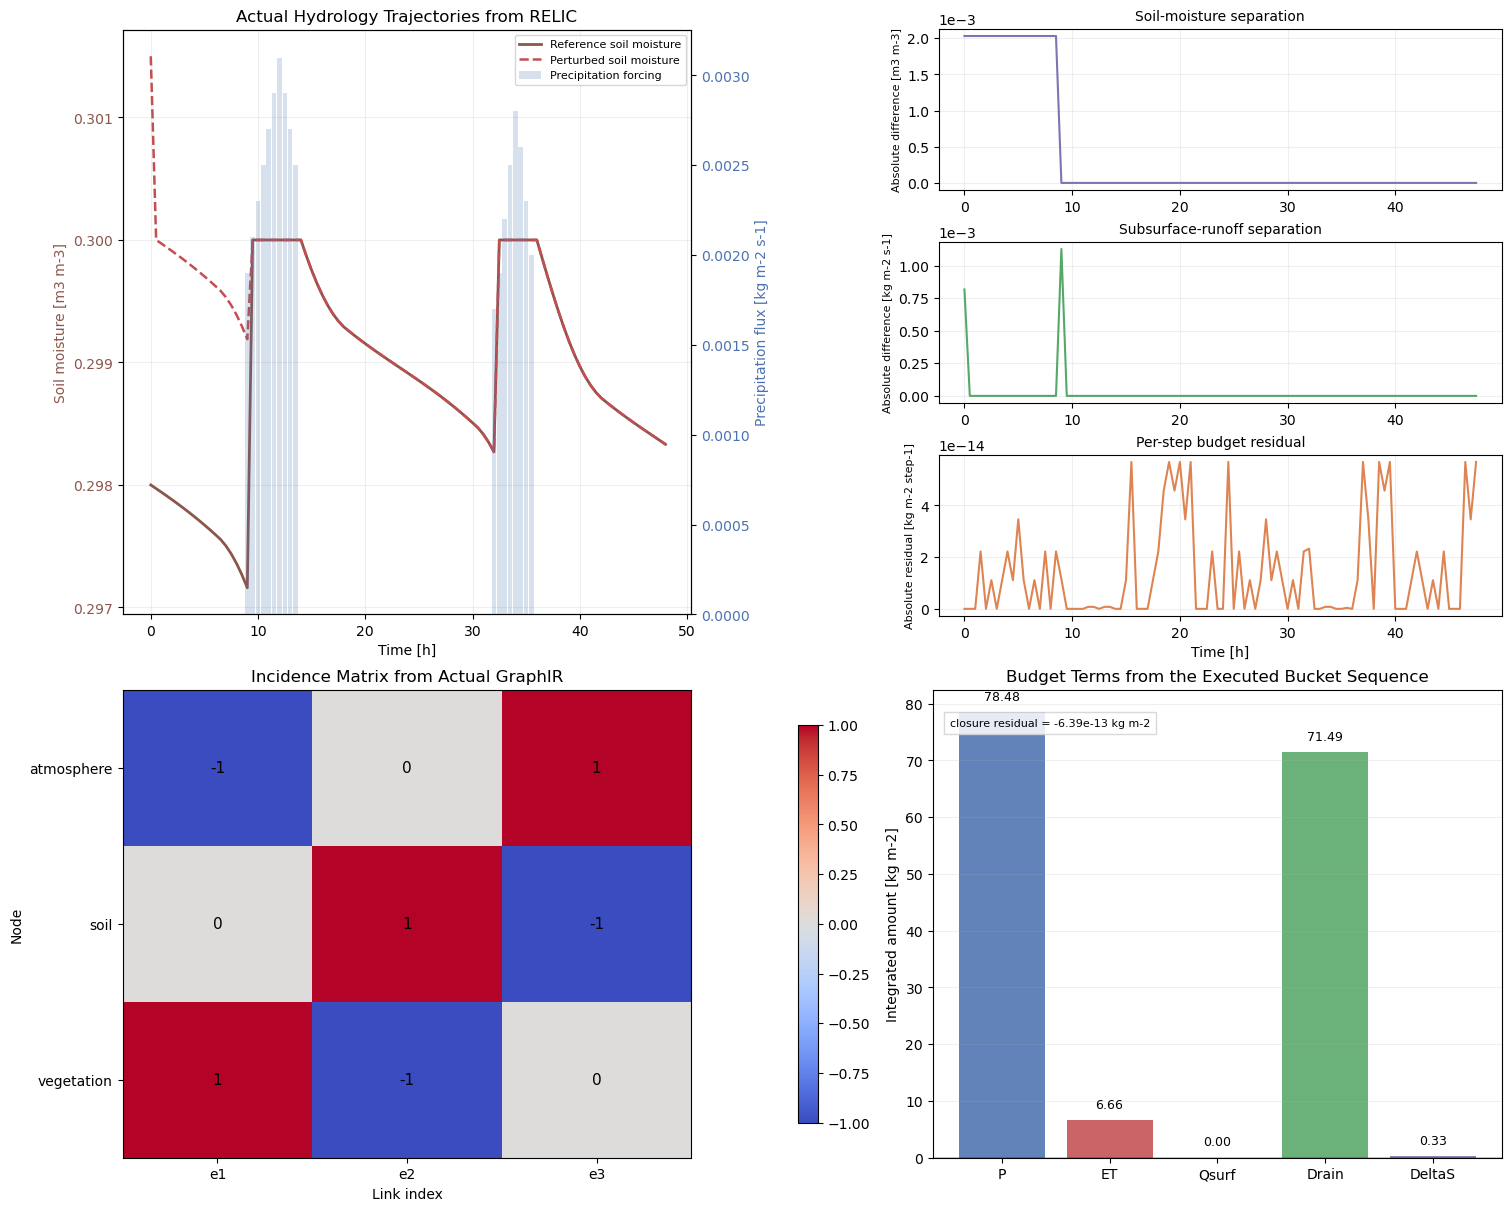

=== Structuralist Foundations Visualization ===
Initial theta separation : 3.500000e-03
Final theta separation   : 0.000000e+00
Relative budget residual : 1.948681e-12
sigma(G)                 : (3, 3, 2, 1, 1)
[OK] NB13 visualization now uses executed RELIC trajectories, GraphIR topology, and actual water-balance terms.


In [7]:
# === NB13: Structural Evidence from Actual RELIC Output ===
import matplotlib.pyplot as plt

reference_time = hydro_ref['time_hours'].tolist()
state_time = torch.cat([torch.zeros(1, dtype=torch.float32), hydro_ref['time_hours'] + (reference_time[1] - reference_time[0])]).tolist()

precip_total = float(torch.sum(hydro_ref['precipitation_flux'] * 1800.0).item())
et_total = float(torch.sum(hydro_ref['evapotranspiration_flux'] * 1800.0).item())
runoff_total = float(torch.sum(hydro_ref['bucket_surface_runoff_flux'] * 1800.0).item())
drainage_total = float(torch.sum(hydro_ref['drainage_flux'] * 1800.0).item())
storage_delta_total = float((hydro_ref['soil_water_storage'][-1] - hydro_ref['soil_water_storage'][0]).item())
step_budget_abs = torch.abs(hydro_ref['budget_residual'])
closure_residual = precip_total - et_total - runoff_total - drainage_total - storage_delta_total

fig = plt.figure(figsize=(15, 12), constrained_layout=True)
layout = fig.add_gridspec(2, 2, height_ratios=[1.25, 1.0])
axes = {position: fig.add_subplot(layout[position]) for position in [(0, 0), (1, 0), (1, 1)]}
diag_layout = layout[0, 1].subgridspec(3, 1)
diag_axes = [fig.add_subplot(diag_layout[row, 0]) for row in range(3)]

theta_ax = axes[0, 0]
precip_ax = theta_ax.twinx()
bar_width = reference_time[1] - reference_time[0] if len(reference_time) > 1 else 0.5
theta_ax.plot(state_time, hydro_ref['soil_moisture'].tolist(), color='#8C564B', lw=2.0, label='Reference soil moisture')
theta_ax.plot(state_time, hydro_pert['soil_moisture'].tolist(), color='#C44E52', lw=1.8, ls='--', label='Perturbed soil moisture')
precip_ax.bar(reference_time, hydro_ref['precipitation_flux'].tolist(), width=0.85 * bar_width, color='#4C72B0', alpha=0.22, label='Precipitation forcing')
theta_ax.set_xlabel('Time [h]')
theta_ax.set_ylabel('Soil moisture [m3 m-3]', color='#8C564B')
precip_ax.set_ylabel('Precipitation flux [kg m-2 s-1]', color='#4C72B0')
theta_ax.tick_params(axis='y', labelcolor='#8C564B')
precip_ax.tick_params(axis='y', labelcolor='#4C72B0')
theta_ax.set_title('Actual Hydrology Trajectories from RELIC')
theta_ax.grid(True, alpha=0.2)
theta_handles, theta_labels = theta_ax.get_legend_handles_labels()
precip_handles, precip_labels = precip_ax.get_legend_handles_labels()
theta_ax.legend(theta_handles + precip_handles, theta_labels + precip_labels, fontsize=8, loc='upper right')

# Display the existing arrays on separate linear axes with their own physical units.
# Zero and roundoff-scale values are shown directly; no log floor changes the display data.
diagnostic_panels = [
    ('Soil-moisture separation', moisture_divergence, 'Absolute difference [m3 m-3]', '#8172B2'),
    ('Subsurface-runoff separation', subsurface_divergence, 'Absolute difference [kg m-2 s-1]', '#55A868'),
    ('Per-step budget residual', step_budget_abs, 'Absolute residual [kg m-2 step-1]', '#DD8452'),
]
for diag_ax, (title, series, units, color) in zip(diag_axes, diagnostic_panels):
    diag_ax.plot(reference_time, series.tolist(), lw=1.5, color=color)
    diag_ax.set_ylabel(units, fontsize=8)
    diag_ax.set_title(title, fontsize=10)
    diag_ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
    diag_ax.grid(True, alpha=0.2)
diag_axes[-1].set_xlabel('Time [h]')

ax = axes[1, 0]
image = ax.imshow(B_torch.tolist(), cmap='coolwarm', vmin=-1.0, vmax=1.0, aspect='auto')
ax.set_xticks(range(m))
ax.set_xticklabels([f'e{idx + 1}' for idx in range(m)])
ax.set_yticks(range(n))
ax.set_yticklabels(node_ids)
ax.set_title('Incidence Matrix from Actual GraphIR')
ax.set_xlabel('Link index')
ax.set_ylabel('Node')
for row_idx in range(n):
    for col_idx in range(m):
        ax.text(col_idx, row_idx, f'{int(B_torch[row_idx, col_idx].item())}', ha='center', va='center', fontsize=11, color='black')
plt.colorbar(image, ax=ax, shrink=0.85)

ax = axes[1, 1]
bar_labels = ['P', 'ET', 'Qsurf', 'Drain', 'DeltaS']
bar_values = [precip_total, et_total, runoff_total, drainage_total, storage_delta_total]
bar_colors = ['#4C72B0', '#C44E52', '#DD8452', '#55A868', '#8172B2']
bars = ax.bar(bar_labels, bar_values, color=bar_colors, alpha=0.88)
ax.axhline(0.0, color='black', lw=1.0)
ax.set_ylabel('Integrated amount [kg m-2]')
ax.set_title('Budget Terms from the Executed Bucket Sequence')
ax.grid(True, axis='y', alpha=0.2)
annotation_pad = 0.02 * max(abs(value) for value in bar_values)
for bar, value in zip(bars, bar_values):
    text_y = value + annotation_pad if value >= 0.0 else value - annotation_pad
    va = 'bottom' if value >= 0.0 else 'top'
    ax.text(bar.get_x() + bar.get_width() / 2.0, text_y, f'{value:.2f}', ha='center', va=va, fontsize=9)
ax.text(
    0.03,
    0.94,
    f'closure residual = {closure_residual:.2e} kg m-2',
    transform=ax.transAxes,
    fontsize=8,
    va='top',
    bbox={'facecolor': 'white', 'alpha': 0.85, 'edgecolor': 'lightgray'},
)

plt.show()
print('=== Structuralist Foundations Visualization ===')
print(f'Initial theta separation : {initial_theta_separation:.6e}')
print(f'Final theta separation   : {final_theta_separation:.6e}')
print(f'Relative budget residual : {relative_budget_residual:.6e}')
print(f'sigma(G)                 : ({n}, {m}, {rank}, {kappa}, {beta_1})')
print('[OK] NB13 visualization now uses executed RELIC trajectories, GraphIR topology, and actual water-balance terms.')

In [8]:
# Quick verification: the notebook is using actual RELIC topology and hydrology modules
print('[OK] Imported modules for NB13 verification:')
print(f'  GraphIR                 : {GraphIR.__name__}')
print(f'  build_incidence_matrix  : {build_incidence_matrix.__name__}')
print(f'  get_topology_signature  : {get_topology_signature.__name__}')
print(f'  PenmanMonteithET        : {PenmanMonteithET.__name__}')
print(f'  BucketSoilMoisture      : {BucketSoilMoisture.__name__}')
print(f'  SurfaceRunoff           : {SurfaceRunoff.__name__}')
print(f'  SubsurfaceRunoff        : {SubsurfaceRunoff.__name__}')

[OK] Imported modules for NB13 verification:
  GraphIR                 : GraphIR
  build_incidence_matrix  : build_incidence_matrix
  get_topology_signature  : get_topology_signature
  PenmanMonteithET        : PenmanMonteithET
  BucketSoilMoisture      : BucketSoilMoisture
  SurfaceRunoff           : SurfaceRunoff
  SubsurfaceRunoff        : SubsurfaceRunoff


## Summary

### Key Takeaways

1. **RELIC does not promise trajectory accuracy.** For systems and domains with a positive Lyapunov exponent,
   trajectories diverge exponentially beyond the Lyapunov predictability horizon
   $T_p \approx \frac{1}{\lambda_{\max}} \ln(\Delta_{\max}/\|\delta x_0\|)$.

2. **RELIC promises structural auditing.** Conservation laws, topological invariants,
   and budget residuals have explicit mathematical and numerical premises.
   A discrete step and an empirical process must satisfy their own contracts.

3. **The incidence matrix $\mathbf{B}$** is the central algebraic object. Its
   left null space $\ker(\mathbf{B}^\top)$ gives conservation vectors; its right
   null space $\ker(\mathbf{B})$ gives unobservable cycle flows.

4. **The three-layer evidence chain** (Structure -> Budget -> Stability) converts
   "model credibility" from subjective narrative into checkable mathematics.

### Next Steps

- **NB14**: Use RELIC's `topology_algebra` API to build and audit real Functor graphs
- **NB15**: Category theory as RELIC's design language (scale lattice, adjunctions)

The topology example and standalone hydrology probes do not establish a
strict IPHS/GENERIC certificate or a registered combined watershed model.
